# Exercise 9: CNN


## CIFAR-10 classification using Keras Conv2D

The CIFAR-10 small photo classification problem is a standard dataset used in computer vision and deep learning.


## CIFAR-10 Photo Classification Dataset

CIFAR comes from the Canadian Institute For Advanced Research and the CIFAR-10 dataset was developed along with the CIFAR-100 dataset by researchers at the CIFAR institute. The dataset is comprised of 60,000 32×32 pixel color photographs of objects from 10 classes with following class labels:

0. airplane
1. automobile
2. bird
3. cat
4. deer
5. dog
6. frog
7. horse
8. ship
9. truck

![Alt text](https://student.labranet.jamk.fi/~rmika/images/ciraf-10.png)

It is relatively straightforward to achieve 80% classification accuracy. Top performance on the problem is achieved by deep learning convolutional neural networks with a classification accuracy above 90% on the test dataset.

__This exercises HAVE TO be done in CSC Puhti cloud environment.__

__NOTE: Try to get as good as possible accuracy. Accurary is one of the evalution criteria__.

TOP results will be found from [here](https://student.labranet.jamk.fi/~rmika/DLNN/TOP-scores.htm)



## 1. Setup and imports

In [1]:
import os, time, random
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, regularizers
from tensorflow.keras.datasets import cifar10
from tensorflow.keras.utils import to_categorical

# Use all CPU cores that SLURM gave us (must be set before TensorFlow runs any operation)
n_cpu = int(os.environ.get("SLURM_CPUS_PER_TASK", os.cpu_count() or 1))
try:
    tf.config.threading.set_intra_op_parallelism_threads(n_cpu)
    tf.config.threading.set_inter_op_parallelism_threads(2)
except RuntimeError:
    pass
print("CPU cores used:", n_cpu)
print("TensorFlow:", tf.__version__)
gpus = tf.config.list_physical_devices("GPU")
print("GPUs:", gpus)
for g in gpus:
    tf.config.experimental.set_memory_growth(g, True)

SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)

CLASS_NAMES = ["airplane", "automobile", "bird", "cat", "deer",
               "dog", "frog", "horse", "ship", "truck"]

I0000 00:00:1795424838.203058 2582976 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1795424838.207374 2582976 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1795424839.280012 2582976 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1795424841.929466 2582976 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_E

CPU cores used: 8
TensorFlow: 2.21.0
GPUs: []


E0000 00:00:1795424843.332304 2582976 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


## 2. Load and inspect data

Train: (50000, 32, 32, 3) (50000, 1)
Test:  (10000, 32, 32, 3) (10000, 1)
Class counts (train): [5000 5000 5000 5000 5000 5000 5000 5000 5000 5000]


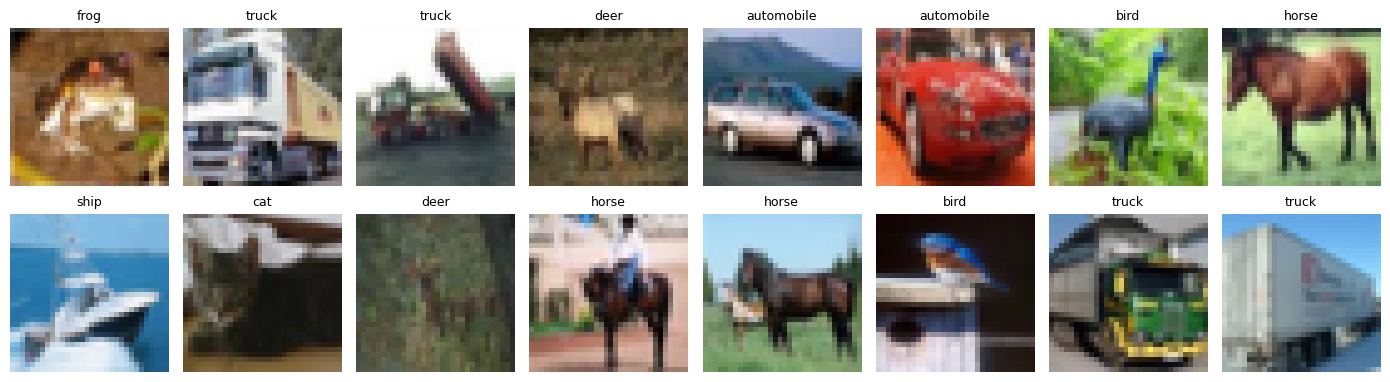

In [2]:
import pickle

def load_batch(path):
    with open(path, "rb") as f:
        d = pickle.load(f, encoding="bytes")
    x = d[b"data"].reshape(-1, 3, 32, 32).transpose(0, 2, 3, 1)
    y = np.array(d[b"labels"]).reshape(-1, 1)
    return x, y

root = os.path.expanduser("~/data/cifar-10-batches-py")
parts = [load_batch(f"{root}/data_batch_{i}") for i in range(1, 6)]
x_train_full = np.concatenate([p[0] for p in parts])
y_train_full = np.concatenate([p[1] for p in parts])
x_test, y_test = load_batch(f"{root}/test_batch")

print("Train:", x_train_full.shape, y_train_full.shape)
print("Test: ", x_test.shape, y_test.shape)
print("Class counts (train):", np.bincount(y_train_full.ravel()))

fig, axes = plt.subplots(2, 8, figsize=(14, 4))
for i, ax in enumerate(axes.ravel()):
    ax.imshow(x_train_full[i]); ax.set_title(CLASS_NAMES[y_train_full[i, 0]], fontsize=9); ax.axis("off")
plt.tight_layout(); plt.show()

## 3. Preprocessing

- Per-channel mean/std normalisation (statistics from the training data only)
- One-hot encoding of labels
- 5,000 training images are held out as a **validation set** (used for choosing the best epoch); the 10,000 test images are used only once, at the end.

In [3]:
x_train_full = x_train_full.astype("float32")
x_test = x_test.astype("float32")

mean = x_train_full.mean(axis=(0, 1, 2))
std = x_train_full.std(axis=(0, 1, 2))
x_train_full = (x_train_full - mean) / std
x_test = (x_test - mean) / std

y_train_full_cat = to_categorical(y_train_full, 10)
y_test_cat = to_categorical(y_test, 10)

# Validation split (fixed, reproducible)
rng = np.random.RandomState(SEED)
idx = rng.permutation(len(x_train_full))
val_idx, tr_idx = idx[:5000], idx[5000:]
x_val, y_val = x_train_full[val_idx], y_train_full_cat[val_idx]
x_train, y_train = x_train_full[tr_idx], y_train_full_cat[tr_idx]
print(x_train.shape, x_val.shape, x_test.shape)

BATCH_SIZE = 128
AUTOTUNE = tf.data.AUTOTUNE
train_ds = (tf.data.Dataset.from_tensor_slices((x_train, y_train))
            .shuffle(10000, seed=SEED).batch(BATCH_SIZE).prefetch(AUTOTUNE))
val_ds = tf.data.Dataset.from_tensor_slices((x_val, y_val)).batch(256).prefetch(AUTOTUNE)
test_ds = tf.data.Dataset.from_tensor_slices((x_test, y_test_cat)).batch(256).prefetch(AUTOTUNE)

(45000, 32, 32, 3) (5000, 32, 32, 3) (10000, 32, 32, 3)


## 4. Model

Smaller VGG-style CNN (32 -> 64 -> 128 filters, about 0.3 M parameters, roughly 6x cheaper than the GPU version), extended from the basic Conv2D/MaxPooling approach in the hint article with the following improvements:

| Technique | Why |
|---|---|
| 3 blocks x 2 conv layers (32 -> 64 -> 128 filters), 3x3, `same` padding | more depth/capacity than the baseline, still CPU-friendly |
| Batch Normalization after each conv | faster, more stable training, allows higher learning rate |
| Progressive Dropout (0.2 -> 0.3 -> 0.4) + dense dropout 0.5 | regularisation against overfitting |
| L2 weight decay | regularisation |
| Data augmentation (flip, shift) | effectively more training data; active only during training |
| SGD + Nesterov momentum with cosine learning-rate decay | strong, well-known recipe for CIFAR-10 |
| Label smoothing (0.1) | reduces over-confidence, small accuracy gain |

In [4]:
WEIGHT_DECAY = 5e-4

def conv_bn_relu(x, filters):
    x = layers.Conv2D(filters, 3, padding="same", use_bias=False,
                      kernel_initializer="he_normal",
                      kernel_regularizer=regularizers.l2(WEIGHT_DECAY))(x)
    x = layers.BatchNormalization()(x)
    return layers.Activation("relu")(x)

def conv_block(x, filters, dropout):
    x = conv_bn_relu(x, filters)
    x = conv_bn_relu(x, filters)
    x = layers.MaxPooling2D(2)(x)
    return layers.Dropout(dropout)(x)

def build_model():
    inputs = keras.Input(shape=(32, 32, 3))
    # Data augmentation (only active in training mode)
    x = layers.RandomFlip("horizontal")(inputs)
    x = layers.RandomTranslation(0.1, 0.1, fill_mode="reflect")(x)

    x = conv_block(x, 32, 0.2)
    x = conv_block(x, 64, 0.3)
    x = conv_block(x, 128, 0.4)

    x = layers.Flatten()(x)
    x = layers.Dense(128, use_bias=False, kernel_initializer="he_normal",
                     kernel_regularizer=regularizers.l2(WEIGHT_DECAY))(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)
    x = layers.Dropout(0.5)(x)
    outputs = layers.Dense(10, activation="softmax")(x)
    return keras.Model(inputs, outputs, name="cifar10_vgg_bn_small")

model = build_model()
model.summary()

Model: "cifar10_vgg_bn_small"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_flip (RandomFlip)        │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_translation              │ (None, 32, 32, 3)      │             0 │
│ (RandomTranslation)             │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 32, 32, 32)     │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 32, 32, 32)     │         9,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 16, 16, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 16, 16, 64)     │        36,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 8, 8, 128)      │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 8, 8, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_4 (Activation)       │ (None, 8, 8, 128)      │             

 Total params: 552,298 (2.11 MB)

 Trainable params: 551,146 (2.10 MB)

 Non-trainable params: 1,152 (4.50 KB)

## 5. Compile and train

Cosine learning-rate decay from 0.05 to ~0 over all epochs. The best model (highest validation accuracy) is stored in `best_cifar10.weights.h5`.

**Settings to adjust:** `EPOCHS` (start with 3, then raise it) and `MAX_MINUTES`, a safety limit that stops training before your Puhti time limit ends so the results are not lost.

In [5]:
EPOCHS = 100
MAX_MINUTES = 200   # stop training after this many minutes (keep below your session time limit)
steps_per_epoch = int(np.ceil(len(x_train) / BATCH_SIZE))

lr_schedule = keras.optimizers.schedules.CosineDecay(
    initial_learning_rate=0.05,
    decay_steps=EPOCHS * steps_per_epoch,
    alpha=1e-3)

model.compile(
    optimizer=keras.optimizers.SGD(learning_rate=lr_schedule, momentum=0.9, nesterov=True),
    loss=keras.losses.CategoricalCrossentropy(label_smoothing=0.1),
    metrics=["accuracy"])

ckpt = keras.callbacks.ModelCheckpoint(
    "best_cifar10.weights.h5", monitor="val_accuracy", mode="max",
    save_best_only=True, save_weights_only=True, verbose=0)

class TimeLimit(keras.callbacks.Callback):
    def __init__(self, max_minutes):
        super().__init__(); self.max_s = max_minutes * 60
    def on_train_begin(self, logs=None):
        self.t0 = time.time()
    def on_epoch_end(self, epoch, logs=None):
        print(f"  elapsed: {(time.time() - self.t0) / 60:.1f} min")
        if time.time() - self.t0 > self.max_s:
            print("Time limit reached - stopping training.")
            self.model.stop_training = True

t0 = time.time()
history = model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS,
                    callbacks=[ckpt, TimeLimit(MAX_MINUTES)], verbose=2)
print(f"Training time: {(time.time() - t0) / 60:.1f} min")

Epoch 1/100


/users/bishtdin/.local/x86_64/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


  elapsed: 0.3 min
352/352 - 17s - 48ms/step - accuracy: 0.3842 - loss: 2.3704 - val_accuracy: 0.4356 - val_loss: 2.2256
Epoch 2/100
  elapsed: 0.5 min
352/352 - 15s - 44ms/step - accuracy: 0.5198 - loss: 1.9746 - val_accuracy: 0.5240 - val_loss: 1.9252
Epoch 3/100
  elapsed: 0.8 min
352/352 - 15s - 43ms/step - accuracy: 0.6008 - loss: 1.7408 - val_accuracy: 0.4930 - val_loss: 2.0545
Epoch 4/100
  elapsed: 1.0 min
352/352 - 15s - 44ms/step - accuracy: 0.6480 - loss: 1.5962 - val_accuracy: 0.5918 - val_loss: 1.6687
Epoch 5/100
  elapsed: 1.3 min
352/352 - 15s - 44ms/step - accuracy: 0.6770 - loss: 1.5017 - val_accuracy: 0.6794 - val_loss: 1.4709
Epoch 6/100
  elapsed: 1.6 min
352/352 - 15s - 44ms/step - accuracy: 0.6976 - loss: 1.4366 - val_accuracy: 0.6820 - val_loss: 1.4350
Epoch 7/100
  elapsed: 1.8 min
352/352 - 15s - 44ms/step - accuracy: 0.7134 - loss: 1.3905 - val_accuracy: 0.6976 - val_loss: 1.3946
Epoch 8/100
  elapsed: 2.1 min
352/352 - 15s - 44ms/step - accuracy: 0.7249 - los

## 6. Learning curves

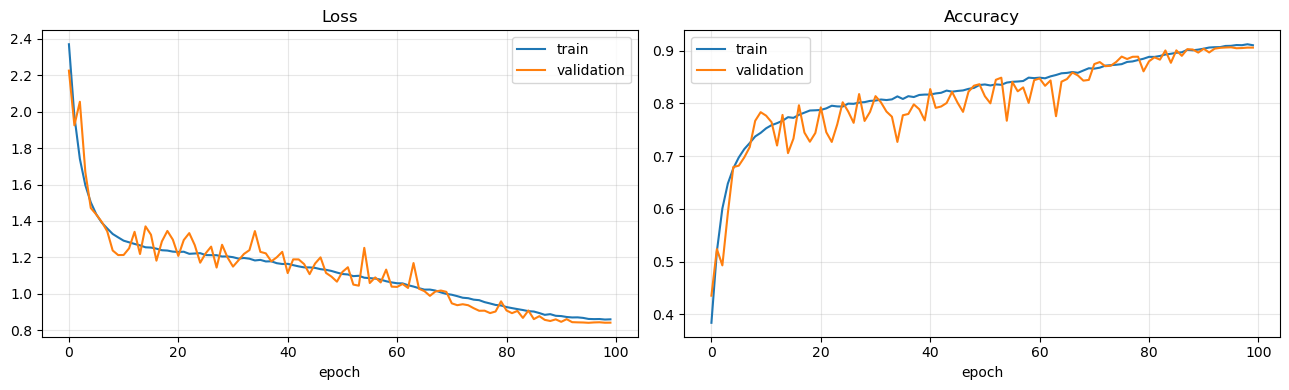

Best epoch: 96, val acc: 0.9064


In [6]:
h = history.history
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].plot(h["loss"], label="train"); ax[0].plot(h["val_loss"], label="validation")
ax[0].set_title("Loss"); ax[0].set_xlabel("epoch"); ax[0].legend(); ax[0].grid(alpha=.3)
ax[1].plot(h["accuracy"], label="train"); ax[1].plot(h["val_accuracy"], label="validation")
ax[1].set_title("Accuracy"); ax[1].set_xlabel("epoch"); ax[1].legend(); ax[1].grid(alpha=.3)
plt.tight_layout(); plt.show()

best_ep = int(np.argmax(h["val_accuracy"]))
print(f"Best epoch: {best_ep + 1}, val acc: {h['val_accuracy'][best_ep]:.4f}")

## 7. Final evaluation on the test set

The best checkpoint (by validation accuracy) is loaded and evaluated on the untouched test set. 
Test-time augmentation (horizontal flip averaging) is also tried as a cheap extra boost.

In [7]:
model.load_weights("best_cifar10.weights.h5")

test_loss, test_acc = model.evaluate(test_ds, verbose=0)
print(f"Test accuracy: {test_acc:.4f}  ({test_acc*100:.2f} %)   loss: {test_loss:.4f}")

# Test-time augmentation: average predictions of image and its horizontal flip
p = model.predict(x_test, batch_size=256, verbose=0)
p_flip = model.predict(x_test[:, :, ::-1, :], batch_size=256, verbose=0)
y_true = y_test.ravel()
acc_plain = np.mean(p.argmax(1) == y_true)
acc_tta = np.mean((p + p_flip).argmax(1) == y_true)
print(f"Plain: {acc_plain:.4f} | With flip TTA: {acc_tta:.4f}")

Test accuracy: 0.8971  (89.71 %)   loss: 0.8565
Plain: 0.8971 | With flip TTA: 0.9041


## 8. Error analysis

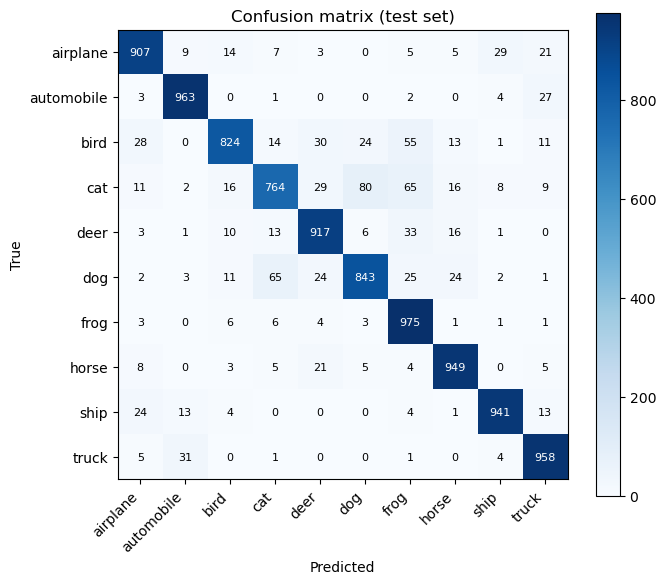

cat          0.764
bird         0.824
dog          0.843
airplane     0.907
deer         0.917
ship         0.941
horse        0.949
truck        0.958
automobile   0.963
frog         0.975


In [8]:
y_pred = (p + p_flip).argmax(1)

# Confusion matrix (plain numpy)
cm = np.zeros((10, 10), dtype=int)
for t, pr in zip(y_true, y_pred):
    cm[t, pr] += 1

fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(cm, cmap="Blues")
ax.set_xticks(range(10)); ax.set_xticklabels(CLASS_NAMES, rotation=45, ha="right")
ax.set_yticks(range(10)); ax.set_yticklabels(CLASS_NAMES)
for i in range(10):
    for j in range(10):
        ax.text(j, i, cm[i, j], ha="center", va="center",
                color="white" if cm[i, j] > cm.max() / 2 else "black", fontsize=8)
ax.set_xlabel("Predicted"); ax.set_ylabel("True"); ax.set_title("Confusion matrix (test set)")
plt.colorbar(im); plt.tight_layout(); plt.show()

# Per-class accuracy
per_class = cm.diagonal() / cm.sum(1)
for name, a in sorted(zip(CLASS_NAMES, per_class), key=lambda t: t[1]):
    print(f"{name:12s} {a:.3f}")

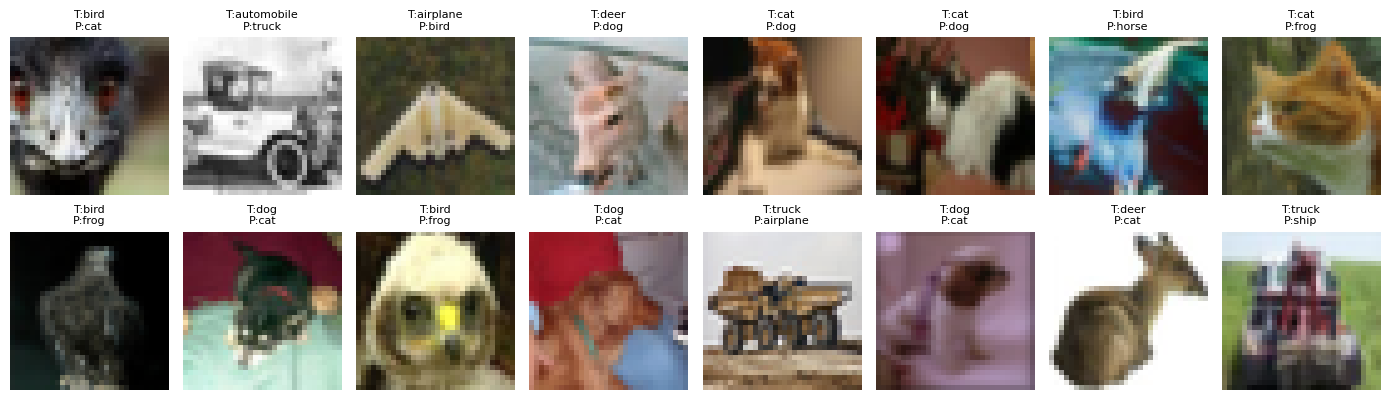

In [9]:
# Some misclassified test images
wrong = np.where(y_pred != y_true)[0]
fig, axes = plt.subplots(2, 8, figsize=(14, 4.2))
for ax, i in zip(axes.ravel(), wrong[:16]):
    img = x_test[i] * std + mean
    ax.imshow(np.clip(img / 255.0, 0, 1))
    ax.set_title(f"T:{CLASS_NAMES[y_true[i]]}\nP:{CLASS_NAMES[y_pred[i]]}", fontsize=8)
    ax.axis("off")
plt.tight_layout(); plt.show()

In [10]:
model.save("cifar10_cnn_final.keras")
print("Model saved.")

Model saved.


# Conclusion

__NOTE: Conclusion is one evaluation criterion for the exercise, so pay attention to writing this__

> **Fill in the numbers in `[ ]` after running the notebook in Puhti.** Replace the text with your own observations.

## Results
- Final test accuracy: **[xx.xx] %** (with flip TTA: **[xx.xx] %**); best validation accuracy **[xx.xx] %** at epoch **[N]**.
- Training: **[N] epochs**, **[N] min** in total (**[N] min/epoch**) on Puhti CPU with **[N] cores**; reduced model (0.3 M parameters) because no GPU was available.
- Weakest classes were **[cat, dog, bird ...]**, mostly confused with each other (see confusion matrix) - visually similar animal classes at only 32x32 pixels. Strongest: **[automobile, ship, truck ...]**.
- Training vs. validation curves: **[describe gap / overfitting level]**.

## Development process
1. **Baseline** (hint article): simple 1-3 VGG blocks with Flatten + Dense gives about 70-83 % and overfits quickly. 
2. **Added Batch Normalization** - training became much more stable and converged faster. 
3. **Added Dropout and L2 weight decay** to reduce the gap between train and validation accuracy. 
4. **Added data augmentation** (flip, shift, zoom) - the largest single gain against overfitting. 
5. **Optimizer/schedule:** SGD + Nesterov momentum with cosine decay, which let the network settle in a good minimum at the end of training. 
6. **Label smoothing and flip TTA** gave small additional improvements.
7. Hyperparameters tried / things that did not help: **[fill in your own experiments, e.g. different learning rates, dropout rates, epochs, batch size]**.

## Observations and possible improvements
- With a GPU, a wider network (64-128-256 filters) trained for 100 epochs should reach clearly higher accuracy; here the model size and epoch count were limited by CPU-only training time.
- Deeper/wider network or ResNet-style skip connections could reach 94-95 %.
- Stronger augmentation (Cutout, MixUp, CutMix, AutoAugment) and longer training are the next steps.
- Ensembling several models would add roughly another 0.5-1 %.
